# 20組で「指示の影響」と「説明文の情報」を確認する

Phi、20組・40概念。元の3組を含みます。各概念の評価20文は5説明×4表現であり、独立20文ではありません。学習文の分け方を5通りに変えます。

**T4 GPUで「すべてのセルを実行」**。6,901回の内部特徴抽出後、CPUで200 Probeとラベルシャッフル対照を計算します。回答は生成しません。主位置は前回と同じ層31・回答開始直前、補助位置は説明文末尾です。

抽出は100入力ごとに保存します。同じランタイム・同じOUTなら抽出セルを再実行して途中から続けられます。ランタイム自体が削除されると途中データも失われます。

最後に検算済みの結果・図・特徴・重みをGitHub mainに自動保存します。シークレット名はGITHUB_TOKEN（別名はSECRET_NAMEで指定）。秘密値はコードへ貼らないでください。これは予備実験であり、本実験の採用や抑制の証明は判定しません。


In [1]:
%pip -q uninstall -y torchaudio torchvision
%pip -q install transformers==4.57.6 accelerate scikit-learn scipy pandas numpy sentencepiece requests matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
timm 1.0.30 requires torchvision, which is not installed.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import sys, subprocess, json, hashlib, torch
assert torch.cuda.is_available(), 'T4 GPUを選んでください。CPUでは実行しません。'
print('GPU:',torch.cuda.get_device_name(0))
REPO=Path('/content/GraduationThesis-instruction-probe20')
if not (REPO/'.git').exists():
    subprocess.run(['git','clone','--depth','1','https://github.com/ryouy/GraduationThesis.git',str(REPO)],check=True)
else:
    subprocess.run(['git','pull','--ff-only'],cwd=REPO,check=True)
FOLDER=REPO/'1104_instruction_probe_20pairs'
frozen=json.loads((FOLDER/'FROZEN_SHA256.json').read_text())
# Verify source before preparing deterministic CSVs; never re-freeze in Colab.
for name,digest in frozen.items():
    if name not in ['training.csv','design.csv']:
        assert hashlib.sha256((FOLDER/name).read_bytes()).hexdigest()==digest,name
subprocess.run([sys.executable,str(FOLDER/'prepare.py')],cwd=REPO,check=True)
for name,digest in frozen.items():
    assert hashlib.sha256((FOLDER/name).read_bytes()).hexdigest()==digest,name
subprocess.run([sys.executable,str(FOLDER/'check.py')],cwd=REPO,check=True)
sys.path.insert(0,str(FOLDER))
from github_save import check_access,save_results,GitHubSaveError
SECRET_NAME='GITHUB_TOKEN'
check_access(SECRET_NAME)
# Re-running setup in this runtime preserves the previous output path.
if 'OUT' not in globals():
    OUT=Path('/content')/('instruction-probe20-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
print('Output:',OUT)


GPU: Tesla T4
GitHub接続確認済み（書込みは実験後の保存時に確認）。トークンは表示しません。
Output: /content/instruction-probe20-20261104T034343105831Z


In [3]:
# Re-run THIS cell to resume extraction from its latest complete checkpoint.
subprocess.run([sys.executable,'-u',str(FOLDER/'extract.py'),'--out',str(OUT)],cwd=REPO,check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/GraduationThesis-instruction-probe20/1104_instruction_probe_20pairs/extract.py', '--out', '/content/instruction-probe20-20261104T034343105831Z'], returncode=0)

,pair,fits_passed,min_auc,max_auc,all_fits_pass
0,banana,5,0.96,1.0,True
1,bicycle,2,1.00,1.0,False
2,boat,4,1.00,1.0,False
3,bread,1,1.00,1.0,False
4,butterfly,4,1.00,1.0,False
5,camera,0,1.00,1.0,False
6,carrot,1,1.00,1.0,False
7,cat,0,1.00,1.0,False
8,clock,0,1.00,1.0,False
9,dolphin,0,1.00,1.0,False


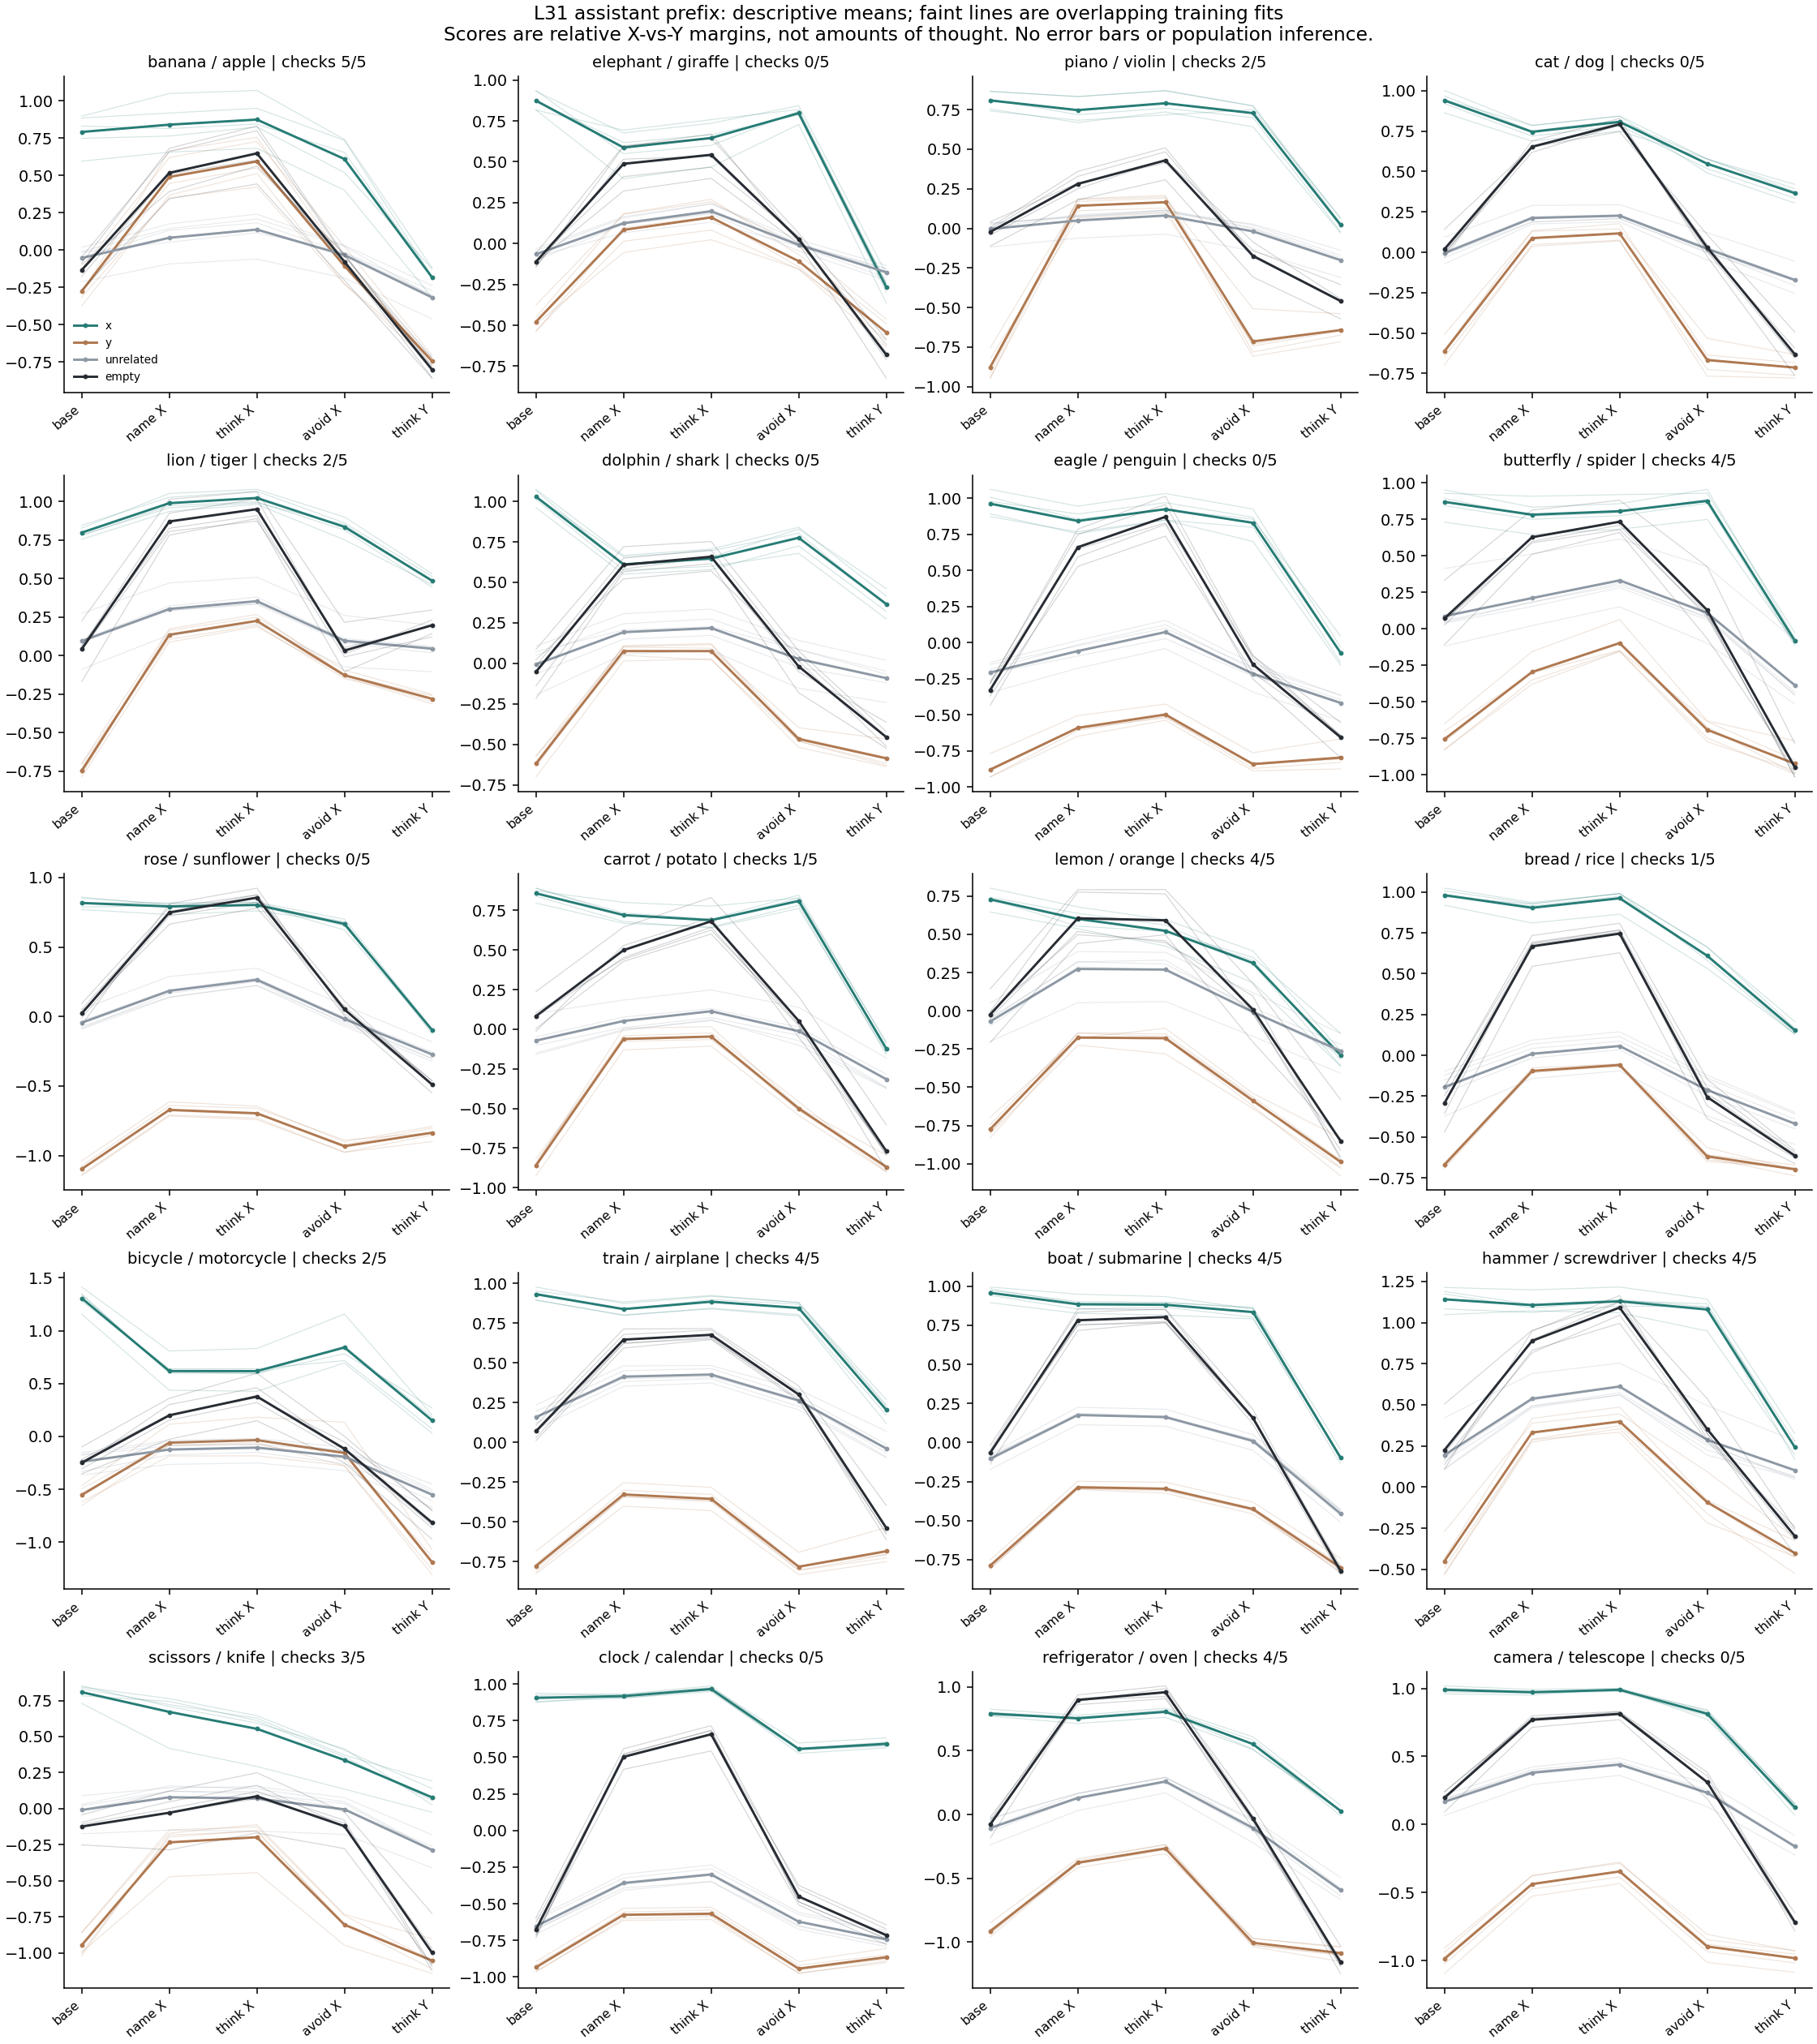

5構成すべての確認を通った組だけが解釈候補です。通過は抑制の証明ではありません。


In [4]:
# All five overlapping training fits reuse the same GPU features.
subprocess.run([sys.executable,'-u',str(FOLDER/'analyze.py'),'--out',str(OUT)],cwd=REPO,check=True)
subprocess.run([sys.executable,str(FOLDER/'make_checksums.py'),str(OUT)],cwd=REPO,check=True)
from IPython.display import display,Image
import pandas as pd
display(pd.read_csv(OUT/'pair_summary.csv'))
display(Image(filename=str(OUT/'comparison.png')))
print('5構成すべての確認を通った組だけが解釈候補です。通過は抑制の証明ではありません。')


In [5]:
# Save only verified complete results. This cell can be retried without GPU work.
import shutil
from google.colab import files
try:
    receipt=save_results(OUT,SECRET_NAME)
    print('GitHub保存確認済み:',receipt['url'])
except GitHubSaveError as exc:
    print(str(exc));print('GitHub保存は未完了です。ZIPを保管して保存セルだけ再実行してください。')
except Exception as exc:
    print('保存前の検算に失敗しました。結果を保管してください。エラー種別:',type(exc).__name__)
finally:
    if OUT.exists():
        # Exclude duplicated private checkpoint directories from the downloadable ZIP.
        import zipfile
        archive=OUT.with_suffix('.zip')
        with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
            for p in OUT.iterdir():
                if p.is_file():z.write(p,p.name)
        files.download(str(archive))


PASS: 6901 inputs, 200 probes, 61000 scores; AUCs, 300 null refits, contrasts and family aggregates verified.
GitHub保存確認済み: https://github.com/ryouy/GraduationThesis/tree/7b63acd4e288469e259e8877bdb737e98ea32bce/1104_instruction_probe_20pairs/results/instruction-probe20-20261104T034343105831Z


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>